<a href="https://colab.research.google.com/github/sabbirpuspo/PGCB-Demand-Aware-Smart-Grid-Optimization/blob/main/PGCB_Demand_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



**Project:** An Intelligent Demand-Aware Optimization Framework for Peak Load Management and Load-Shedding Mitigation in Smart Grids

**Notebook version:** 2.0.0 | **Stage:** Data preparation and baseline experiments

This notebook prepares daily demand profiles from the PGCB workbook and compares two existing scheduling methods with leaving demand unchanged. It establishes the reference results for the project. **It does not implement the proposed new algorithm, an ensemble, or a load-shedding mitigation model.**

### How to run

Upload this `.ipynb` file into Google Colab and run the cells from top to bottom. A standard CPU runtime is sufficient for the calculations here. Keep the default settings for the first run and approve the Google Drive request in Section 3. The workbook is downloaded from UCI automatically; a manual dataset upload is not required. Save your notebook separately using Colab's File menu.

Each numbered section contains a short explanation followed by the code it describes. Section 2 contains the experiment settings. A full run creates a new results folder, so earlier runs remain available.

### What is observed, and what is assumed?

| Item | Treatment in this notebook |
|---|---|
| Historical electricity demand and generation | Read from the PGCB workbook. |
| Tomorrow's demand forecast | Demand at the same clock hour seven days earlier. No forecasting model is trained. |
| Flexible consumption | Hypothetical hourly shift limits of 5%, 10%, or 15% of **forecast** demand, not measured customer flexibility. |
| Scheduled action | Chosen before the target day, then assumed to be delivered in full. |
| Energy | Preserved over each 24-hour scheduling window. Load is shifted, not eliminated. |
| Load shedding, costs, emissions, and grid losses | Not estimated by these baseline experiments. |

The simulation allows moving consumption between any hours within a day. Appliance deadlines, customer participation, network constraints, and real-time control are not represented. A lower simulated peak is therefore not evidence of actual operational savings.

### Evaluation periods

The existing experiment settings are retained: 2023 is reserved for later development, 2024 is the primary retrospective evaluation, and the available part of 2025 is a supplementary temporal evaluation. Earlier project discussions already examined 2024/2025 outcomes; **these periods are not described as untouched holdouts**. Do not choose new parameters by seeking the best results on these periods. A later confirmatory study will need its own frozen protocol.

### Data source

PGCB Hourly Generation Dataset (Bangladesh). UCI Machine Learning Repository (2025). DOI: [10.24432/C59P6V](https://doi.org/10.24432/C59P6V). Dataset license: CC BY 4.0. The original workbook is kept unchanged. The checksum, filtering decisions, software versions, and results are saved for each run.

## 1. Prepare the Python environment

The first cell checks for the libraries needed by the experiment and installs only those that are missing. It then imports the packages used below. There is no GPU training in this notebook.

**Expected output:** confirmation that the environment is ready and whether the notebook is running in Colab.

In [ ]:
import importlib.util
import subprocess
import sys

required_packages = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'matplotlib': 'matplotlib',
    'openpyxl': 'openpyxl',
    'requests': 'requests',
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--quiet', *missing_packages
    ])

import hashlib
import io
import json
import logging
import os
import platform
import shutil
import uuid
import zipfile
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import requests
from IPython.display import display
from requests.adapters import HTTPAdapter
from scipy.optimize import linprog
from urllib3.util.retry import Retry

IS_COLAB = 'google.colab' in sys.modules
print('Environment ready. Running in Colab:', IS_COLAB)


Environment ready. Running in Colab: True


## 2. Set the experiment configuration

All research settings are collected here. Leave them unchanged for the first run so the results are comparable with the original notebook.

The broad demand and generation limits are **preliminary data screens**, not installed-capacity or engineering ratings. The value `0.001` is the original LP movement penalty, not an electricity price. The 5%, 10%, and 15% cases are sensitivity scenarios, not estimated consumer behavior.

`LOCAL_DATASET_PATH` is an optional recovery setting. Leave it as `None` to use the automatic UCI download and Drive cache.

**Expected output:** a readable record of the selected settings.

In [ ]:
NOTEBOOK_VERSION = '2.0.0'
PROJECT_TITLE = (
    'An Intelligent Demand-Aware Optimization Framework for Peak Load '
    'Management and Load-Shedding Mitigation in Smart Grids'
)

CONFIG = {
    'use_google_drive': True,
    'random_seed': 42,
    'forecast_lag_days': 7,
    'hours_per_day': 24,
    'time_step_hours': 1.0,
    'flexibility_fractions': [0.05, 0.10, 0.15],
    'development_year': 2023,
    'evaluation_years': [2024, 2025],
    'demand_screen_mw': [1000.0, 30000.0],
    'generation_screen_mw': [0.0, 30000.0],
    'lp_movement_penalty': 0.001,
    'power_tolerance_mw': 1e-5,
    'energy_tolerance_mwh': 1e-4,
    'example_flexibility': 0.10,
    'sheet_name': None,
}
LOCAL_DATASET_PATH = None

if CONFIG['forecast_lag_days'] < 1:
    raise ValueError('The forecast must use at least one preceding day.')
if not all(0 <= value < 1 for value in CONFIG['flexibility_fractions']):
    raise ValueError('Flexibility fractions must be in [0, 1).')
if CONFIG['hours_per_day'] != 24 or CONFIG['time_step_hours'] != 1.0:
    raise ValueError('This version implements 24 one-hour scheduling intervals.')
if CONFIG['example_flexibility'] not in CONFIG['flexibility_fractions']:
    raise ValueError('The example flexibility must be one of the experiment settings.')
if CONFIG['development_year'] in CONFIG['evaluation_years']:
    raise ValueError('Keep the development period separate from the evaluation periods.')
if len(set(CONFIG['evaluation_years'])) != len(CONFIG['evaluation_years']):
    raise ValueError('Each evaluation year must appear only once.')

np.random.seed(CONFIG['random_seed'])
display(pd.Series(CONFIG, name='setting').to_frame())


,setting
use_google_drive,True
random_seed,42
forecast_lag_days,7
hours_per_day,24
time_step_hours,1.0
flexibility_fractions,"[0.05, 0.1, 0.15]"
development_year,2023
evaluation_years,"[2024, 2025]"
demand_screen_mw,"[1000.0, 30000.0]"
generation_screen_mw,"[0.0, 30000.0]"


## 3. Create a new results folder

In Colab, this cell mounts Google Drive and creates a uniquely named folder under `MyDrive/PGCB_Demand_Optimization/runs/`. The shared `data/` folder holds the original workbook for reuse. Approve the Drive authorization request when it appears.

Each full run receives a new identifier. Re-running later cells updates only that current run; it does not change older run folders. A Drive error stops execution rather than silently switching to temporary storage. Outside Colab, the notebook uses a project folder in the current working directory.

**Expected output:** the dataset-cache location and the current results-folder location.

In [ ]:
if IS_COLAB and CONFIG['use_google_drive']:
    from google.colab import drive
    drive.mount('/content/drive')
    project_root = Path('/content/drive/MyDrive/PGCB_Demand_Optimization')
elif IS_COLAB:
    project_root = Path('/content/PGCB_Demand_Optimization')
    print('Drive saving is disabled. Runtime files may be lost after disconnection.')
else:
    project_root = Path.cwd() / 'PGCB_Demand_Optimization'
    project_root = Path(os.environ.get('PGCB_PROJECT_ROOT', str(project_root)))

DATA_DIR = project_root / 'data'
RUN_ID = (
    'phase1_v2_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    + '_' + uuid.uuid4().hex[:8]
)
RUN_DIR = project_root / 'runs' / RUN_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=False)

logger = logging.getLogger('pgcb_phase1')
logger.setLevel(logging.INFO)
logger.propagate = False
for handler in list(logger.handlers):
    handler.close()
    logger.removeHandler(handler)
file_handler = logging.FileHandler(RUN_DIR / 'run.log', encoding='utf-8')
file_handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
logger.addHandler(file_handler)


def write_json(path: Path, content: dict) -> None:
    path.write_text(json.dumps(content, indent=2, default=str), encoding='utf-8')


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


package_versions = {name: version(name) for name in required_packages.values()}
write_json(RUN_DIR / 'configuration.json', CONFIG)
write_json(RUN_DIR / 'environment.json', {
    'python': platform.python_version(),
    'platform': platform.platform(),
    'packages': package_versions,
    'notebook_version': NOTEBOOK_VERSION,
})
(RUN_DIR / 'requirements_used.txt').write_text(
    '\n'.join(f'{name}=={value}' for name, value in package_versions.items()) + '\n',
    encoding='utf-8',
)
write_json(RUN_DIR / 'run_status.json', {'run_id': RUN_ID, 'status': 'started'})
logger.info('Started %s', RUN_ID)
print('Dataset cache:', DATA_DIR)
print('Results folder:', RUN_DIR)


Mounted at /content/drive
Dataset cache: /content/drive/MyDrive/PGCB_Demand_Optimization/data
Results folder: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase1_v2_20261107T081332Z_748af497


## 4. Obtain the original UCI workbook

The workbook is fetched from the UCI archive only when it is absent from the cache. Existing cached data are not replaced automatically. The download is checked as an Excel archive before it is saved, and a SHA-256 fingerprint is recorded.

The fingerprint identifies the exact file used; it does not prove that its measurements are correct. For a later UCI revision, keep the earlier file and record the new version separately. A corrupt cache produces an explicit error instead of an unrecorded replacement.

**Expected output:** the acquisition mode, file size, and source fingerprint. No manual upload is needed on a normal first run.

In [ ]:
UCI_PAGE = 'https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset+(bangladesh)'
UCI_ARCHIVE = (
    'https://archive.ics.uci.edu/static/public/1175/'
    'pgcb%2Bhourly%2Bgeneration%2Bdataset%2B%28bangladesh%29.zip'
)
DATASET_DOI = '10.24432/C59P6V'
DATA_PATH = DATA_DIR / 'PGCB_date_power_demand.xlsx'


def check_excel_archive(path: Path) -> None:
    if not path.is_file() or path.stat().st_size < 1000:
        raise ValueError(f'The workbook is missing or unexpectedly small: {path}')
    try:
        with zipfile.ZipFile(path) as archive:
            if 'xl/workbook.xml' not in archive.namelist():
                raise ValueError('The file is not a valid .xlsx workbook.')
            corrupt_member = archive.testzip()
            if corrupt_member is not None:
                raise ValueError(f'Corrupt Excel member: {corrupt_member}')
    except zipfile.BadZipFile as error:
        raise ValueError(f'Invalid Excel archive: {path}') from error


if DATA_PATH.exists():
    acquisition_mode = 'reused_cache'
    check_excel_archive(DATA_PATH)
elif LOCAL_DATASET_PATH is not None:
    supplied_path = Path(LOCAL_DATASET_PATH)
    check_excel_archive(supplied_path)
    shutil.copy2(supplied_path, DATA_PATH)
    acquisition_mode = 'user_supplied_file'
else:
    acquisition_mode = 'downloaded_from_uci'
    temporary_path = DATA_DIR / f'.{RUN_ID}.download.xlsx'
    retry = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
    try:
        with requests.Session() as session:
            session.mount('https://', HTTPAdapter(max_retries=retry))
            response = session.get(UCI_ARCHIVE, timeout=(15, 180))
            response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
            members = [
                name for name in archive.namelist()
                if Path(name).name.lower() == DATA_PATH.name.lower()
            ]
            if len(members) != 1:
                raise ValueError(f'Expected one source workbook; found {members}.')
            with archive.open(members[0]) as source, temporary_path.open('wb') as target:
                shutil.copyfileobj(source, target)
        check_excel_archive(temporary_path)
        temporary_path.replace(DATA_PATH)
    except Exception as error:
        temporary_path.unlink(missing_ok=True)
        raise RuntimeError(
            'The UCI download could not be completed. Retry this cell. '
            'Alternatively, set LOCAL_DATASET_PATH in Section 2 to a valid '
            f'copy of the original workbook. Details: {error}'
        ) from error

source_hash = sha256_file(DATA_PATH)
source_manifest = {
    'run_id': RUN_ID,
    'dataset_doi': DATASET_DOI,
    'dataset_page': UCI_PAGE,
    'archive_url': UCI_ARCHIVE,
    'filename': DATA_PATH.name,
    'source_xlsx_sha256': source_hash,
    'file_size_bytes': DATA_PATH.stat().st_size,
    'acquisition_mode': acquisition_mode,
    'recorded_at_utc': datetime.now(timezone.utc).isoformat(),
    'license': 'CC BY 4.0 (dataset)',
}
write_json(RUN_DIR / 'source_manifest.json', source_manifest)
logger.info('Source acquired: %s; SHA256=%s', acquisition_mode, source_hash)
print('Source:', acquisition_mode)
print('File:', DATA_PATH.name, '| Bytes:', DATA_PATH.stat().st_size)
print('SHA-256:', source_hash)


Source: downloaded_from_uci
File: PGCB_date_power_demand.xlsx | Bytes: 7121844
SHA-256: cd10a95b98033594b70ff176d69e9feaa2ade5f43b8ae4e5640a0f9deabc9da1


## 5. Read the worksheet and inspect its columns

The original notebook read the first worksheet. This version keeps that default and prints the worksheet names so the choice is visible. The workbook is opened read-only, and the complete worksheet is scanned rather than trusting its declared dimensions.

Only `demand_mw` drives the scheduling experiment. `generation_mw` is retained for the original quality screen, and `load_shedding` is retained as contextual data. Fuel-source columns are audited but are not optimization inputs.

**Expected output:** worksheet names, row and column counts, and the first five records.

In [ ]:
workbook = openpyxl.load_workbook(DATA_PATH, read_only=True, data_only=True)
try:
    worksheet_names = workbook.sheetnames
    selected_sheet = CONFIG['sheet_name'] or worksheet_names[0]
    if selected_sheet not in worksheet_names:
        raise ValueError(f'Worksheet {selected_sheet!r} is not present.')
    worksheet = workbook[selected_sheet]
    worksheet.reset_dimensions()
    row_iterator = worksheet.iter_rows(values_only=True)
    headers = list(next(row_iterator))
    if any(header is None for header in headers) or len(set(headers)) != len(headers):
        raise ValueError('The worksheet contains blank or duplicate column names.')
    raw = pd.DataFrame(row_iterator, columns=headers)
finally:
    workbook.close()

required_columns = {'datetime', 'demand_mw', 'generation_mw', 'load_shedding'}
missing_columns = required_columns.difference(raw.columns)
if missing_columns:
    raise ValueError(f'Required columns are absent: {sorted(missing_columns)}')

print('Worksheets:', worksheet_names)
print('Selected worksheet:', selected_sheet)
print(f'Loaded {len(raw):,} rows and {len(raw.columns)} columns.')
display(raw.head())
source_manifest.update({'worksheet': selected_sheet, 'rows': len(raw), 'columns': list(raw.columns)})
write_json(RUN_DIR / 'source_manifest.json', source_manifest)


Worksheets: ['Sheet1']
Selected worksheet: Sheet1
Loaded 92,650 rows and 15 columns.


,datetime,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal,remarks
0,2015-04-19 22:00:00,6323,6323,0,0,0,0,0,nan,nan,0,0,nan,nan,None
1,2015-04-19 21:00:00,6667,6667,0,0,0,0,0,nan,nan,0,0,nan,nan,None
2,2015-04-19 19:00:00,6897,6897,0,4415,1836,161,41,nan,nan,444,0,nan,nan,None
3,2015-04-19 18:30:00,6933,6933,0,4423,1862,159,45,nan,nan,444,0,nan,nan,Evening_Peak
4,2015-04-19 18:00:00,6874,6874,0,4319,1892,155,65,nan,nan,443,0,nan,nan,None


## 6. Audit timestamps and measurements

This cell reports missing or unparseable values, repeated timestamps, off-hour observations, and gaps in the raw time sequence. It does not remove records yet. Workbook row numbers are retained later in the exclusion report so questionable observations can be traced back to the source.

Timestamps are treated as the source's local clock, without a timezone conversion. The count of rows belonging to duplicate groups differs from the number of extra duplicate rows; both are reported. Missing fuel-source observations are not replaced with zero.

**Expected output:** a compact quality summary and a per-column missing-value table.

In [ ]:
data = raw.copy()
data['datetime'] = pd.to_datetime(data['datetime'], errors='coerce')
numeric_columns = [name for name in raw.columns if name not in ('datetime', 'remarks')]
for name in numeric_columns:
    data[name] = pd.to_numeric(data[name], errors='coerce')

valid_timestamp = data['datetime'].notna()
on_hour = (
    valid_timestamp
    & data['datetime'].dt.minute.eq(0)
    & data['datetime'].dt.second.eq(0)
    & data['datetime'].dt.microsecond.eq(0)
)
duplicate_timestamp = valid_timestamp & data['datetime'].duplicated(keep=False)
unique_times = pd.DatetimeIndex(data.loc[valid_timestamp, 'datetime'].unique()).sort_values()
if len(unique_times) == 0:
    raise ValueError('No usable timestamps were found.')
interval_minutes = pd.Series(unique_times).diff().dt.total_seconds().div(60).dropna()

audit = {
    'original_rows': len(raw),
    'original_columns': len(raw.columns),
    'first_timestamp': str(unique_times.min()),
    'last_timestamp': str(unique_times.max()),
    'missing_or_unparseable_timestamps': int((~valid_timestamp).sum()),
    'off_hour_rows': int((valid_timestamp & ~on_hour).sum()),
    'rows_in_duplicate_timestamp_groups': int(duplicate_timestamp.sum()),
    'extra_duplicate_timestamp_rows': int(data.loc[valid_timestamp, 'datetime'].duplicated().sum()),
    'distinct_duplicate_timestamps': int(data.loc[duplicate_timestamp, 'datetime'].nunique()),
    'fully_duplicate_rows': int(raw.duplicated().sum()),
    'raw_unique_time_gaps_over_one_hour': int(interval_minutes.gt(60).sum()),
    'largest_raw_gap_hours': float(interval_minutes.max() / 60) if len(interval_minutes) else None,
}
missing_report = pd.DataFrame({
    'column': raw.columns,
    'missing_in_workbook': [int(raw[name].isna().sum()) for name in raw.columns],
    'missing_after_parsing': [int(data[name].isna().sum()) for name in raw.columns],
})
missing_report['newly_unparseable'] = (
    missing_report['missing_after_parsing'] - missing_report['missing_in_workbook']
)
pd.Series(audit, name='value').to_csv(RUN_DIR / 'initial_audit.csv')
missing_report.to_csv(RUN_DIR / 'missing_values.csv', index=False)
interval_minutes.value_counts().sort_index().rename_axis('minutes').rename('count').to_csv(
    RUN_DIR / 'raw_timestamp_intervals.csv'
)
display(pd.Series(audit, name='value').to_frame())
display(missing_report)


,value
original_rows,92650
original_columns,15
first_timestamp,2015-04-19 00:00:00
last_timestamp,2025-06-17 12:00:00
missing_or_unparseable_timestamps,0
off_hour_rows,4181
rows_in_duplicate_timestamp_groups,813
extra_duplicate_timestamp_rows,432
distinct_duplicate_timestamps,381
fully_duplicate_rows,160


,column,missing_in_workbook,missing_after_parsing,newly_unparseable
0,datetime,0,0,0
1,generation_mw,0,0,0
2,demand_mw,0,0,0
3,load_shedding,0,0,0
4,gas,0,0,0
5,liquid_fuel,0,0,0
6,coal,0,0,0
7,hydro,0,0,0
8,solar,0,22133,22133
9,wind,0,73974,73974


## 7. Build the hourly research subset

The original conservative filtering rules are preserved: keep on-hour readings, exclude every duplicate-timestamp group, and apply the broad demand/generation screens from Section 2. No outlier values are corrected by guesswork, and no missing hours are interpolated.

A target day must contain all 24 hourly readings. This improves traceability but can exclude unusual or difficult days, so the results apply to the retained subset rather than automatically to the entire national-grid record. The generation screen is retained for comparability even though generation is not a scheduler input.

**Expected output:** retention counts by year. `excluded_source_rows.csv` records overlapping exclusion reasons; their totals should not be added together.

In [ ]:
demand_low, demand_high = CONFIG['demand_screen_mw']
generation_low, generation_high = CONFIG['generation_screen_mw']
flags = pd.DataFrame({
    'invalid_timestamp': ~valid_timestamp,
    'off_hour_timestamp': valid_timestamp & ~on_hour,
    'duplicate_timestamp': duplicate_timestamp,
    'unusable_demand': ~data['demand_mw'].between(demand_low, demand_high),
    'unusable_generation': ~data['generation_mw'].between(generation_low, generation_high),
}, index=data.index)
keep_row = ~flags.any(axis=1)

excluded = raw.loc[~keep_row].copy()
excluded.insert(0, 'source_excel_row', excluded.index + 2)
excluded['exclusion_reasons'] = flags.loc[~keep_row].apply(
    lambda row: ';'.join(row.index[row.to_numpy(dtype=bool)]), axis=1
)
excluded.to_csv(RUN_DIR / 'excluded_source_rows.csv', index=False)
flags.sum().rename('flagged_rows').to_csv(RUN_DIR / 'exclusion_reason_counts.csv')

hourly = (
    data.loc[keep_row, ['datetime', 'demand_mw', 'generation_mw', 'load_shedding']]
    .sort_values('datetime')
    .set_index('datetime')
)
if not hourly.index.is_unique or not hourly.index.is_monotonic_increasing:
    raise RuntimeError('The retained hourly index is not unique and ordered.')
hourly['year'] = hourly.index.year
hourly['day'] = hourly.index.normalize()
retained_counts = hourly.groupby('day').size()
full_days = pd.DatetimeIndex(retained_counts[retained_counts.eq(24)].index)
complete = hourly.loc[hourly['day'].isin(full_days)].copy()
if complete.empty:
    raise RuntimeError('No complete 24-hour days remain after screening.')

hourly.to_csv(RUN_DIR / 'clean_hourly_points.csv.gz', compression='gzip')
complete.to_csv(RUN_DIR / 'clean_hourly_complete_days.csv.gz', compression='gzip')
coverage = pd.DataFrame({
    'raw_rows': data.groupby(data['datetime'].dt.year).size(),
    'retained_hourly_rows': hourly.groupby('year').size(),
    'complete_days': pd.Series(full_days.year).value_counts(),
}).fillna(0).astype(int).sort_index()
coverage.index = coverage.index.astype(int)
coverage.index.name = 'year'
coverage.to_csv(RUN_DIR / 'data_coverage_by_year.csv')
print(f'Retained {len(hourly):,} hourly readings and {len(full_days):,} complete days.')
display(coverage)


Retained 87,653 hourly readings and 3,184 complete days.


,raw_rows,retained_hourly_rows,complete_days
year,,,
2015,6659,5994,183
2016,9490,8672,291
2017,8486,8019,265
2018,9091,8634,293
2019,9060,8642,318
2020,9146,8753,338
2021,9126,8735,343
2022,9135,8717,327
2023,9121,8716,326


## 8. Construct day-ahead forecast cases

For each target hour, the forecast is the observed demand at the same hour seven days earlier:

$$\widehat{D}_{d,h}=D_{d-7,h},\qquad h=0,\ldots,23.$$

This is a seasonal-naive reference forecast, not a trained machine-learning model. Every historical input must precede the beginning of the target day. A case is excluded when either its target-day profile or its required historical profile is incomplete. These exclusions are saved explicitly.

Observed target-day demand is carried alongside the forecast **only for subsequent evaluation**. Scheduling functions receive the forecast, never that future observed profile. Values observed on earlier evaluation days may be used for later forecasts, as they would be in sequential operation.

**Expected output:** eligible-day counts for 2023, 2024, and 2025. No 2023 scheduling evaluation is performed here.

In [ ]:
def make_daily_cases(year: int) -> tuple[list[dict], pd.DataFrame]:
    cases, eligibility = [], []
    first_day = pd.Timestamp(year=year, month=1, day=1)
    last_day = min(pd.Timestamp(year=year, month=12, day=31), unique_times.max().normalize())
    if last_day < first_day:
        return cases, pd.DataFrame(columns=['date', 'year', 'status'])

    demand_values = hourly['demand_mw'].to_numpy(dtype=float)
    for day in pd.date_range(first_day, last_day, freq='D'):
        target_hours = pd.date_range(day, periods=24, freq='h')
        history_hours = target_hours - pd.Timedelta(days=CONFIG['forecast_lag_days'])
        target_positions = hourly.index.get_indexer(target_hours)
        history_positions = hourly.index.get_indexer(history_hours)
        if np.any(target_positions < 0):
            status = 'incomplete_target_day'
        elif np.any(history_positions < 0):
            status = 'incomplete_forecast_history'
        else:
            if history_hours.max() >= day:
                raise RuntimeError('A forecast input does not precede its target day.')
            actual = demand_values[target_positions].copy()
            forecast = demand_values[history_positions].copy()
            if not (np.isfinite(actual).all() and np.isfinite(forecast).all()):
                raise RuntimeError('A forecast case contains non-finite demand.')
            cases.append({
                'day': day,
                'actual': actual,
                'forecast': forecast,
                'latest_forecast_input': history_hours.max(),
            })
            status = 'eligible'
        eligibility.append({'date': str(day.date()), 'year': year, 'status': status})
    return cases, pd.DataFrame(eligibility)


years_to_prepare = [CONFIG['development_year'], *CONFIG['evaluation_years']]
cases_by_year, eligibility_tables = {}, []
for year in years_to_prepare:
    cases_by_year[year], eligibility = make_daily_cases(year)
    eligibility_tables.append(eligibility)
    print(f'{year}: {len(cases_by_year[year])} eligible forecast days')

eligibility_report = pd.concat(eligibility_tables, ignore_index=True)
eligibility_report.to_csv(RUN_DIR / 'daily_case_eligibility.csv', index=False)
for year in CONFIG['evaluation_years']:
    if not cases_by_year[year]:
        raise RuntimeError(f'No eligible cases for {year}; inspect the eligibility report.')
print('The development year is prepared but is not evaluated by this notebook.')


2023: 295 eligible forecast days
2024: 317 eligible forecast days
2025: 151 eligible forecast days
The development year is prepared but is not evaluated by this notebook.


## 9. Define the unchanged-demand and fixed-rule methods

The **NoChange** reference makes no scheduling adjustment. The **FixedRule** baseline identifies the six largest and six smallest forecast hours, takes energy from the largest hours, and reallocates it to the smallest hours in proportion to their forecast-based limits. This is the same ranking and allocation rule as the original notebook.

Let $x_h$ be the scheduled change in MW. Negative values remove consumption from an hour; positive values add it elsewhere. Both scheduling methods must satisfy

$$\sum_h x_h\Delta t=0,\qquad |x_h|\leq\alpha\widehat{D}_h,$$

where $\Delta t=1$ hour and $\alpha$ is the assumed flexibility fraction. The simple rule is not guaranteed to reduce every peak, especially when the forecast is inaccurate or the original profile is nearly flat.

**Expected output:** confirmation that the reference methods are defined. No experiments run in this cell.

In [ ]:
def validate_scheduler_inputs(predicted: np.ndarray, alpha: float) -> np.ndarray:
    predicted = np.asarray(predicted, dtype=float)
    if predicted.shape != (24,) or not np.isfinite(predicted).all():
        raise ValueError('The scheduler requires 24 finite forecast values.')
    if np.any(predicted <= 0):
        raise ValueError('Forecast demand must be strictly positive.')
    if not np.isfinite(alpha) or not 0 <= alpha < 1:
        raise ValueError('The flexibility fraction must be in [0, 1).')
    return predicted


def no_change_schedule(predicted: np.ndarray, alpha: float) -> np.ndarray:
    predicted = validate_scheduler_inputs(predicted, alpha)
    return np.zeros_like(predicted)


def fixed_rule_schedule(predicted: np.ndarray, alpha: float) -> np.ndarray:
    predicted = validate_scheduler_inputs(predicted, alpha)
    adjustment = np.zeros_like(predicted)
    ranked_hours = np.argsort(predicted)
    hours_per_group = len(predicted) // 4
    low_hours = ranked_hours[:hours_per_group]
    high_hours = ranked_hours[-hours_per_group:]

    low_limits = alpha * predicted[low_hours]
    high_limits = alpha * predicted[high_hours]
    transfer = min(low_limits.sum(), high_limits.sum())
    if transfer == 0:
        return adjustment

    adjustment[low_hours] = transfer * low_limits / low_limits.sum()
    adjustment[high_hours] = -transfer * high_limits / high_limits.sum()
    return adjustment


print('NoChange and FixedRule are defined.')


NoChange and FixedRule are defined.


## 10. Define the linear-programming baseline

The LP baseline selects all 24 adjustments jointly. It retains the original objective and constraints:

$$\min_{x,a,z}\quad z+\lambda\sum_h a_h,$$

$$\widehat{D}_h+x_h\leq z,\quad a_h\geq x_h,\quad a_h\geq-x_h,$$

$$\sum_h x_h=0,\qquad -\alpha\widehat{D}_h\leq x_h\leq\alpha\widehat{D}_h.$$

Here, $z$ bounds the forecast peak, $a_h$ represents absolute movement, and $\lambda=0.001$ discourages unnecessary movement. All objective terms use MW in this fixed hourly formulation. This is a weighted peak-and-movement objective, not a cost model or a newly invented algorithm.

SciPy's `linprog` calls the HiGHS solver. The cell checks the solver's success flag rather than accepting a failed solution. Optimality concerns this **forecast-based objective**, not the unknown realized peak.

**Expected output:** confirmation that the LP method is defined.

In [ ]:
def lp_peak_schedule(predicted: np.ndarray, alpha: float) -> np.ndarray:
    predicted = validate_scheduler_inputs(predicted, alpha)
    penalty = CONFIG['lp_movement_penalty']
    if not np.isfinite(penalty) or penalty < 0:
        raise ValueError('The LP movement penalty must be finite and non-negative.')
    n_hours = len(predicted)

    # Decision vector: hourly adjustments, their absolute values, then the peak.
    objective = np.zeros(2 * n_hours + 1)
    objective[n_hours:2 * n_hours] = penalty
    objective[-1] = 1.0
    inequalities = np.zeros((3 * n_hours, 2 * n_hours + 1))
    upper_bounds = np.zeros(3 * n_hours)

    for hour in range(n_hours):
        inequalities[hour, hour] = 1.0
        inequalities[hour, -1] = -1.0
        upper_bounds[hour] = -predicted[hour]
        inequalities[n_hours + hour, hour] = 1.0
        inequalities[n_hours + hour, n_hours + hour] = -1.0
        inequalities[2 * n_hours + hour, hour] = -1.0
        inequalities[2 * n_hours + hour, n_hours + hour] = -1.0

    energy_balance = np.zeros((1, 2 * n_hours + 1))
    energy_balance[0, :n_hours] = 1.0
    variable_bounds = [(-alpha * float(value), alpha * float(value)) for value in predicted]
    variable_bounds += [(0, None)] * n_hours + [(0, None)]

    solution = linprog(
        objective,
        A_ub=inequalities,
        b_ub=upper_bounds,
        A_eq=energy_balance,
        b_eq=[0.0],
        bounds=variable_bounds,
        method='highs',
    )
    if not solution.success:
        raise RuntimeError(f'LP failed ({solution.status}): {solution.message}')
    return solution.x[:n_hours]


METHODS = {
    'NoChange': no_change_schedule,
    'FixedRule': fixed_rule_schedule,
    'LP': lp_peak_schedule,
}
print('LP is defined. Comparison methods:', ', '.join(METHODS))


LP is defined. Comparison methods: NoChange, FixedRule, LP


## 11. Define feasibility checks and evaluation measures

Schedules are applied to recorded demand only after they have been chosen from the forecast:

$$D^{\mathrm{sim}}_h=D^{\mathrm{observed}}_h+x_h.$$

The daily peak-reduction percentage compares the maxima of the observed and simulated profiles. Shifted energy is $\tfrac12\sum_h|x_h|\Delta t$; the factor of one-half avoids counting the same energy twice. Energy conservation and forecast-based shift bounds are checked for every schedule. Physically negative simulated demand causes a failure, not silent clipping.

The notebook also reports hours in which a scheduled adjustment exceeds $\alpha$ times **observed** demand. This is a separate after-the-fact diagnostic; it is not used to choose or repair schedules. An action feasible under a forecast-based limit is not necessarily feasible under an actual-load-based limit. All reported improvements remain conditional on full delivery of the planned adjustment.

**Expected output:** confirmation that evaluation functions are defined.

In [ ]:
def check_planned_schedule(predicted: np.ndarray, adjustment: np.ndarray, alpha: float) -> None:
    predicted = validate_scheduler_inputs(predicted, alpha)
    adjustment = np.asarray(adjustment, dtype=float)
    if adjustment.shape != predicted.shape or not np.isfinite(adjustment).all():
        raise ValueError('The schedule must contain 24 finite adjustments.')
    energy_error = abs(adjustment.sum() * CONFIG['time_step_hours'])
    if energy_error > CONFIG['energy_tolerance_mwh']:
        raise RuntimeError(f'Daily energy is not conserved: {energy_error} MWh.')
    if np.any(np.abs(adjustment) > alpha * predicted + CONFIG['power_tolerance_mw']):
        raise RuntimeError('A forecast-based shift bound was exceeded.')


def evaluate_day(case: dict, adjustment: np.ndarray, method: str, alpha: float, year: int) -> dict:
    actual, forecast = case['actual'], case['forecast']
    check_planned_schedule(forecast, adjustment, alpha)
    simulated = actual + adjustment
    if np.any(simulated < -CONFIG['power_tolerance_mw']):
        raise RuntimeError(f'Negative simulated demand on {case["day"].date()}; inspect feasibility.')

    step = CONFIG['time_step_hours']
    observed_peak = float(actual.max())
    simulated_peak = float(simulated.max())
    peak_reduction = observed_peak - simulated_peak
    actual_limit_excess = np.maximum(np.abs(adjustment) - alpha * actual, 0.0)
    return {
        'date': str(case['day'].date()),
        'year': year,
        'method': method,
        'alpha': alpha,
        'baseline_peak_mw': observed_peak,
        'scheduled_peak_mw': simulated_peak,
        'peak_reduction_mw': peak_reduction,
        'peak_reduction_pct': 100.0 * peak_reduction / observed_peak,
        'peak_increased': peak_reduction < -CONFIG['power_tolerance_mw'],
        'predicted_peak_mw': float(forecast.max()),
        'scheduled_predicted_peak_mw': float((forecast + adjustment).max()),
        'moved_energy_mwh': float(np.abs(adjustment).sum() * step / 2),
        'baseline_energy_mwh': float(actual.sum() * step),
        'scheduled_energy_mwh': float(simulated.sum() * step),
        'energy_balance_error_mwh': float(abs(adjustment.sum() * step)),
        'forecast_mae_mw': float(np.abs(actual - forecast).mean()),
        'forecast_rmse_mw': float(np.sqrt(np.mean((actual - forecast) ** 2))),
        'actual_relative_limit_exceeded_hours': int(
            (actual_limit_excess > CONFIG['power_tolerance_mw']).sum()
        ),
        'max_actual_relative_limit_excess_mw': float(actual_limit_excess.max()),
    }


print('Schedule checks and daily metrics are defined.')


Schedule checks and daily metrics are defined.


## 12. Test the scheduling functions before using the data

These small synthetic checks test implementation behavior, not empirical performance. They cover a peaky profile, a flat profile, a smooth profile, and reproducible random profiles. Zero flexibility must produce no action, energy must be conserved, and all forecast-based limits must hold.

The LP objective is checked against both feasible alternatives. We do not require the fixed rule to improve every profile; doing so would hide a known weakness of a simple peak-to-valley rule. Invalid inputs must raise a useful error.

**Expected output:** the number of successful checks. Execution stops if a check fails.

In [ ]:
rng = np.random.default_rng(CONFIG['random_seed'])
profiles = {
    'peaky': np.array([5] * 18 + [7, 8, 9, 10, 7, 5], dtype=float) * 1000,
    'flat': np.full(24, 8000.0),
    'smooth': np.linspace(5000.0, 12000.0, 24),
}
for index in range(5):
    profiles[f'random_{index + 1}'] = rng.uniform(4000.0, 15000.0, 24)

check_records = []
for profile_name, profile in profiles.items():
    for alpha in [0.0, *CONFIG['flexibility_fractions']]:
        adjustments = {name: function(profile, alpha) for name, function in METHODS.items()}
        for name, adjustment in adjustments.items():
            check_planned_schedule(profile, adjustment, alpha)
            if alpha == 0.0 and not np.allclose(adjustment, 0, atol=1e-5, rtol=0):
                raise AssertionError('Zero flexibility produced a nonzero adjustment.')
        objectives = {
            name: float((profile + adjustment).max()
                        + CONFIG['lp_movement_penalty'] * np.abs(adjustment).sum())
            for name, adjustment in adjustments.items()
        }
        if objectives['LP'] > min(objectives['NoChange'], objectives['FixedRule']) + 1e-4:
            raise AssertionError('LP objective exceeded a feasible comparison objective.')
        check_records.append({'check': f'{profile_name}_alpha_{alpha}', 'passed': True})

invalid_inputs = [
    (np.full(23, 8000.0), 0.10),
    (np.full(24, np.nan), 0.10),
    (np.full(24, -1.0), 0.10),
    (np.full(24, 8000.0), -0.10),
    (np.full(24, 8000.0), 1.0),
]
for index, (profile, alpha) in enumerate(invalid_inputs):
    for name, function in METHODS.items():
        try:
            function(profile, alpha)
        except ValueError:
            check_records.append({'check': f'invalid_{index + 1}_{name}', 'passed': True})
        else:
            raise AssertionError(f'{name} accepted an invalid input.')

self_checks = pd.DataFrame(check_records)
self_checks.to_csv(RUN_DIR / 'implementation_self_checks.csv', index=False)
print(f'Passed {len(self_checks)} implementation checks.')


Passed 47 implementation checks.


## 13. Run the baseline comparison

Each method receives the same forecast, flexibility limit, and evaluation day. The NoChange reference is repeated at each flexibility setting for side-by-side comparison; those repetitions are not additional independent days.

The code saves both daily metrics and hourly schedules. Days on which the peak becomes worse remain in the results. Progress is printed periodically, and the completed results for each year are written before starting the next year. A solver or feasibility error stops the experiment with a recorded failure rather than silently dropping the case.

**Expected output:** progress messages, evaluated-day counts, and confirmation that result tables were saved.

In [ ]:
all_results, all_schedules = [], []
experiment_started = perf_counter()
try:
    for year in CONFIG['evaluation_years']:
        year_results, year_schedules = [], []
        cases = cases_by_year[year]
        print(f'Evaluating {year}: {len(cases)} days')
        for case_index, case in enumerate(cases, start=1):
            for alpha in CONFIG['flexibility_fractions']:
                for method_name, scheduler in METHODS.items():
                    started = perf_counter()
                    adjustment = scheduler(case['forecast'], alpha)
                    elapsed = perf_counter() - started
                    record = evaluate_day(case, adjustment, method_name, alpha, year)
                    record['scheduling_seconds'] = elapsed
                    year_results.append(record)
                    year_schedules.append(pd.DataFrame({
                        'datetime': pd.date_range(case['day'], periods=24, freq='h'),
                        'date': str(case['day'].date()),
                        'year': year,
                        'method': method_name,
                        'alpha': alpha,
                        'observed_demand_mw': case['actual'],
                        'forecast_demand_mw': case['forecast'],
                        'adjustment_mw': adjustment,
                        'simulated_demand_mw': case['actual'] + adjustment,
                        'latest_forecast_input': case['latest_forecast_input'],
                    }))
            if case_index % 50 == 0 or case_index == len(cases):
                print(f'  Completed {case_index}/{len(cases)} days')

        yearly_results = pd.DataFrame(year_results)
        yearly_schedules = pd.concat(year_schedules, ignore_index=True)
        yearly_results.to_csv(RUN_DIR / f'daily_results_{year}.csv', index=False)
        yearly_schedules.to_csv(
            RUN_DIR / f'hourly_schedules_{year}.csv.gz', index=False, compression='gzip'
        )
        all_results.append(yearly_results)
        all_schedules.append(yearly_schedules)
        logger.info('Completed %s: %s evaluation days', year, len(cases))
except Exception as error:
    logger.exception('Baseline evaluation failed')
    write_json(RUN_DIR / 'run_status.json', {
        'run_id': RUN_ID, 'status': 'failed', 'error': str(error),
    })
    raise

results = pd.concat(all_results, ignore_index=True)
schedules = pd.concat(all_schedules, ignore_index=True)
results.to_csv(RUN_DIR / 'day_level_schedule_results.csv', index=False)
experiment_seconds = perf_counter() - experiment_started
print(f'Saved {len(results):,} daily comparison records.')
print(f'Baseline evaluation completed in {experiment_seconds:.1f} seconds in this runtime.')


Evaluating 2024: 317 days
  Completed 50/317 days
  Completed 100/317 days
  Completed 150/317 days
  Completed 200/317 days
  Completed 250/317 days
  Completed 300/317 days
  Completed 317/317 days
Evaluating 2025: 151 days
  Completed 50/151 days
  Completed 100/151 days
  Completed 150/151 days
  Completed 151/151 days
Saved 4,212 daily comparison records.
Baseline evaluation completed in 12.2 seconds in this runtime.


## 14. Summarize improvements and failures

The summary gives the arithmetic mean and median of daily peak-reduction percentages, the worst day, and the percentage of days with a larger simulated peak. Averages are not a substitute for checking downside risk.

The actual-relative-limit diagnostic is reported separately: it identifies days when full delivery would exceed a flexibility budget defined using observed demand. It does not change the original forecast-based optimization. Timing is a runtime measurement, not a hardware-independent algorithm benchmark.

**Expected output:** one summary table per evaluation period. Positive reduction means a lower simulated peak; negative reduction means a higher one.

In [ ]:
summary = results.groupby(['year', 'method', 'alpha'], as_index=False).agg(
    n_days=('date', 'nunique'),
    mean_peak_reduction_pct=('peak_reduction_pct', 'mean'),
    median_peak_reduction_pct=('peak_reduction_pct', 'median'),
    worst_peak_reduction_pct=('peak_reduction_pct', 'min'),
    mean_peak_reduction_mw=('peak_reduction_mw', 'mean'),
    pct_days_peak_worse=('peak_increased', lambda values: 100.0 * values.mean()),
    mean_shifted_energy_mwh=('moved_energy_mwh', 'mean'),
    mean_forecast_mae_mw=('forecast_mae_mw', 'mean'),
    max_energy_error_mwh=('energy_balance_error_mwh', 'max'),
    pct_days_actual_limit_exceeded=(
        'actual_relative_limit_exceeded_hours', lambda values: 100.0 * values.gt(0).mean()
    ),
    mean_scheduling_seconds=('scheduling_seconds', 'mean'),
)
summary.to_csv(RUN_DIR / 'baseline_summary.csv', index=False)

for year in CONFIG['evaluation_years']:
    compared_days = results.loc[results['year'].eq(year)].groupby(['method', 'alpha'])['date'].nunique()
    if not compared_days.eq(len(cases_by_year[year])).all():
        raise AssertionError('Methods were not evaluated on the same days.')
if results['energy_balance_error_mwh'].max() > CONFIG['energy_tolerance_mwh']:
    raise AssertionError('Energy balance check failed.')
if not np.allclose(results.loc[results['method'].eq('NoChange'), 'peak_reduction_mw'], 0):
    raise AssertionError('The NoChange reference was altered.')

visible_columns = [
    'method', 'alpha', 'n_days', 'mean_peak_reduction_pct',
    'worst_peak_reduction_pct', 'pct_days_peak_worse',
    'pct_days_actual_limit_exceeded',
]
for year in CONFIG['evaluation_years']:
    print(f'\n{year}: conditional scheduling-simulation results')
    display(summary.loc[summary['year'].eq(year), visible_columns].round(3))
print('All evaluated days, including negative outcomes, are included.')



2024: conditional scheduling-simulation results


,method,alpha,n_days,mean_peak_reduction_pct,worst_peak_reduction_pct,pct_days_peak_worse,pct_days_actual_limit_exceeded
0,FixedRule,0.05,317,2.876,-4.781,2.208,58.675
1,FixedRule,0.10,317,4.244,-9.561,6.940,58.675
2,FixedRule,0.15,317,3.381,-14.728,23.659,58.675
3,LP,0.05,317,2.260,-6.335,11.672,62.776
4,LP,0.10,317,4.867,-9.326,8.833,58.044
5,LP,0.15,317,6.469,-11.647,8.833,35.647
6,NoChange,0.05,317,0.000,0.000,0.000,0.000
7,NoChange,0.10,317,0.000,0.000,0.000,0.000
8,NoChange,0.15,317,0.000,0.000,0.000,0.000



2025: conditional scheduling-simulation results


,method,alpha,n_days,mean_peak_reduction_pct,worst_peak_reduction_pct,pct_days_peak_worse,pct_days_actual_limit_exceeded
9,FixedRule,0.05,151,2.235,-5.198,7.285,50.331
10,FixedRule,0.10,151,3.067,-10.619,14.570,50.331
11,FixedRule,0.15,151,1.754,-16.040,34.437,50.331
12,LP,0.05,151,1.773,-4.474,21.192,57.616
13,LP,0.10,151,3.548,-6.417,23.179,58.278
14,LP,0.15,151,4.467,-11.666,22.517,39.735
15,NoChange,0.05,151,0.000,0.000,0.000,0.000
16,NoChange,0.10,151,0.000,0.000,0.000,0.000
17,NoChange,0.15,151,0.000,0.000,0.000,0.000


All evaluated days, including negative outcomes, are included.


## 15. Plot peak reduction and downside risk

Each year is shown separately. The first chart compares average daily peak reduction across assumed flexibility levels; the second shows how often a schedule increased the peak. The NoChange method is the zero reference line.

Figures are saved as PNG and SVG files. The graphics describe conditional simulations, not observed improvements to the grid. They use the complete eligible-day results rather than a hand-picked successful period.

**Expected output:** two figures per evaluation year, also saved in the run folder.

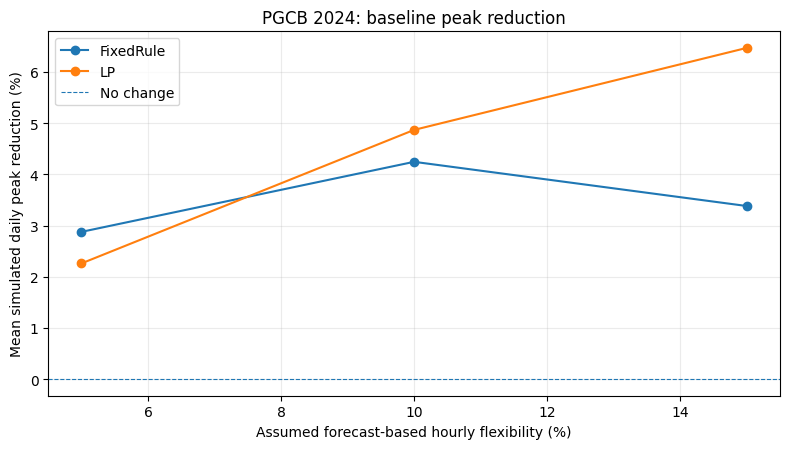

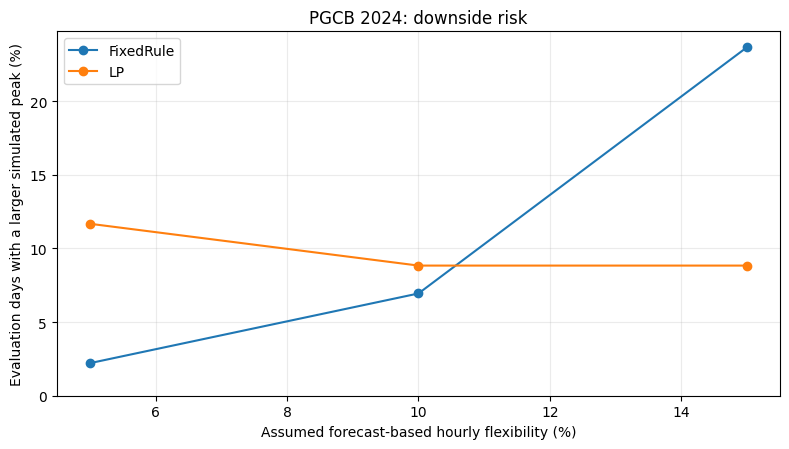

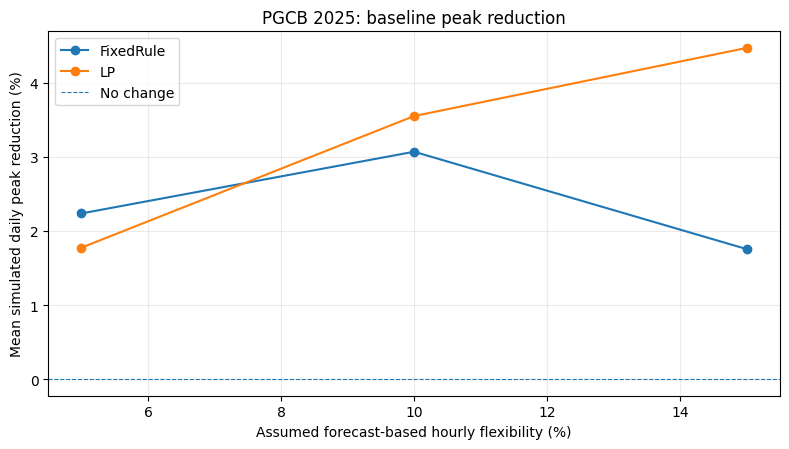

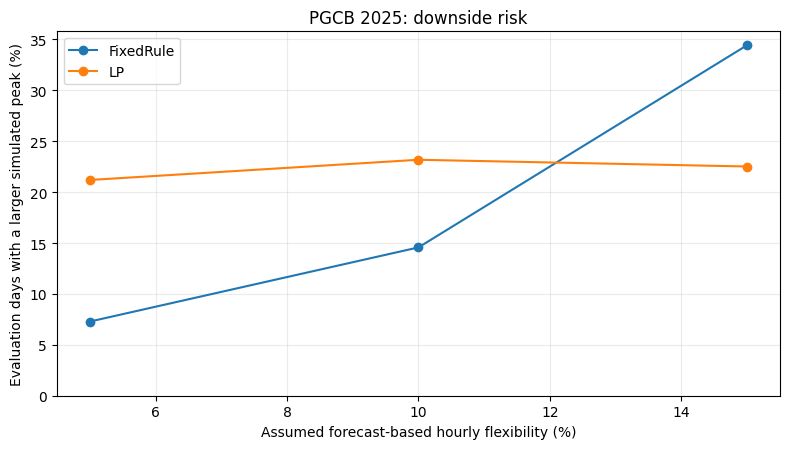

In [ ]:
def save_figure(figure, name: str) -> None:
    figure.tight_layout()
    figure.savefig(RUN_DIR / f'{name}.png', dpi=600, bbox_inches='tight')
    figure.savefig(RUN_DIR / f'{name}.svg', bbox_inches='tight')
    plt.show()
    plt.close(figure)


for year in CONFIG['evaluation_years']:
    year_summary = summary.loc[summary['year'].eq(year)]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for method in ['FixedRule', 'LP']:
        points = year_summary.loc[year_summary['method'].eq(method)].sort_values('alpha')
        ax.plot(points['alpha'] * 100, points['mean_peak_reduction_pct'], marker='o', label=method)
    ax.axhline(0, linewidth=0.8, linestyle='--', label='No change')
    ax.set(
        xlabel='Assumed forecast-based hourly flexibility (%)',
        ylabel='Mean simulated daily peak reduction (%)',
        title=f'PGCB {year}: baseline peak reduction',
    )
    ax.grid(alpha=0.25)
    ax.legend()
    save_figure(fig, f'peak_reduction_{year}')

    fig, ax = plt.subplots(figsize=(8, 4.6))
    for method in ['FixedRule', 'LP']:
        points = year_summary.loc[year_summary['method'].eq(method)].sort_values('alpha')
        ax.plot(points['alpha'] * 100, points['pct_days_peak_worse'], marker='o', label=method)
    ax.set(
        xlabel='Assumed forecast-based hourly flexibility (%)',
        ylabel='Evaluation days with a larger simulated peak (%)',
        title=f'PGCB {year}: downside risk',
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend()
    save_figure(fig, f'peak_increase_frequency_{year}')


## 16. Inspect one daily schedule

For transparency, the example is always the **first eligible day** of each evaluation year at 10% flexibility. It is not selected for an attractive result. Recorded demand, the previous-week forecast, and both simulated schedules are shown together.

The display helps explain why a forecast-based plan may fail: an expected low-demand hour can turn out to be a high-demand hour. The complete hourly schedules are available in the compressed CSV files for inspection beyond this example.

**Expected output:** one daily-profile figure per year, including the date in its title.

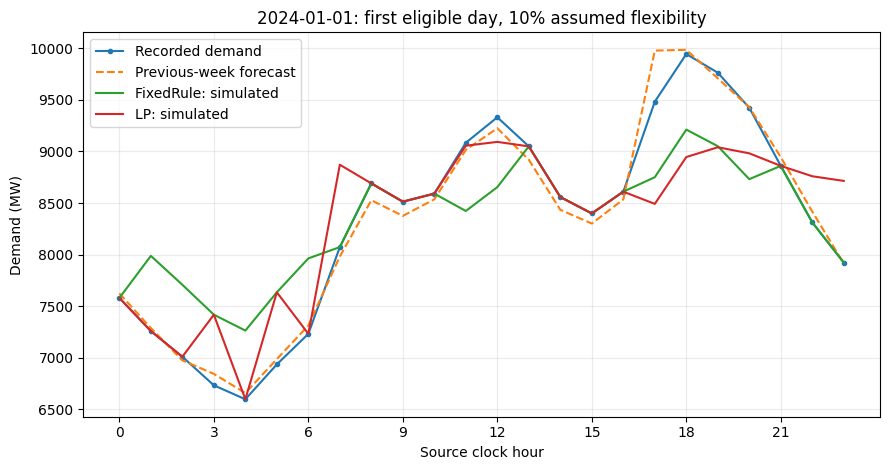

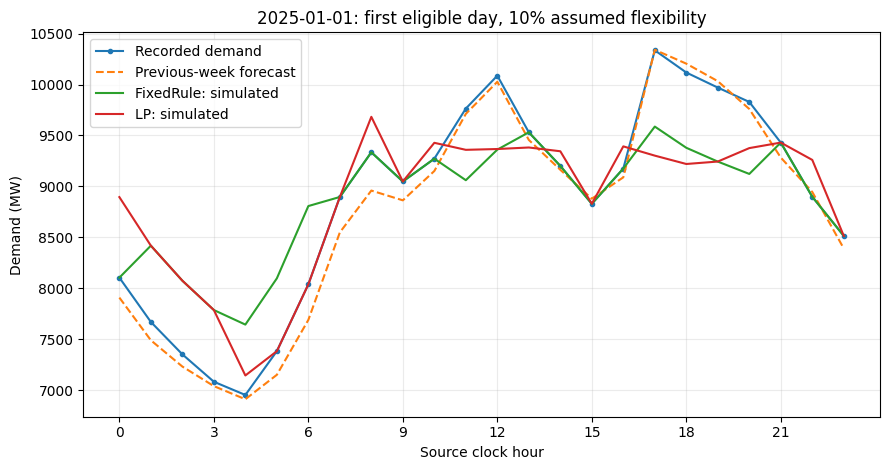

In [ ]:
for year in CONFIG['evaluation_years']:
    case = cases_by_year[year][0]
    date_text = str(case['day'].date())
    example_rows = schedules.loc[
        schedules['year'].eq(year)
        & schedules['date'].eq(date_text)
        & schedules['alpha'].eq(CONFIG['example_flexibility'])
    ]
    hours = np.arange(24)
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(hours, case['actual'], marker='.', label='Recorded demand')
    ax.plot(hours, case['forecast'], linestyle='--', label='Previous-week forecast')
    for method in ['FixedRule', 'LP']:
        profile = example_rows.loc[example_rows['method'].eq(method)].sort_values('datetime')
        ax.plot(hours, profile['simulated_demand_mw'], label=f'{method}: simulated')
    ax.set(
        xlabel='Source clock hour',
        ylabel='Demand (MW)',
        title=f'{date_text}: first eligible day, 10% assumed flexibility',
    )
    ax.set_xticks(np.arange(0, 24, 3))
    ax.grid(alpha=0.25)
    ax.legend()
    save_figure(fig, f'first_eligible_day_{year}')


## 17. Save the research record and verify the outputs

The final cell writes the research protocol, completes the run status, hashes the output files, and packages the results into one ZIP archive. It also verifies that the original workbook fingerprint has not changed.

The archive includes results, audit tables, figures, settings, and the software-version record. **It does not contain the original workbook or the notebook itself.** Save the `.ipynb` separately for GitHub. The dataset can be obtained using its DOI and the source fingerprint.

**Expected output:** the results-folder path, ZIP path, and a list of generated files. A completed status is written only after the preceding checks have succeeded.

In [ ]:
if sha256_file(DATA_PATH) != source_hash:
    raise RuntimeError('The original workbook changed during the experiment.')

protocol = {
    'project_title': PROJECT_TITLE,
    'notebook_version': NOTEBOOK_VERSION,
    'run_id': RUN_ID,
    'phase': 'Baseline scheduling experiments; no proposed new algorithm',
    'dataset_doi': DATASET_DOI,
    'source_xlsx_sha256': source_hash,
    'source_notebook_sha256': '0055895ef2af7d0727212eb235021bca61c763ef6854f40ecadec7a40e0ea985',
    'forecast': 'Same-clock-hour demand from seven days earlier; no model training',
    'methods': list(METHODS),
    'configuration': CONFIG,
    'eligible_days_by_year': {str(year): len(cases_by_year[year]) for year in years_to_prepare},
    'evaluation_status': 'Retrospective; 2024 and 2025 outcomes were previously explored',
    'assumptions': [
        'The flexibility fraction limits hourly movement relative to forecast demand.',
        'Planned adjustments are assumed to be fully delivered.',
        'Daily energy is conserved; no load is permanently removed.',
        'Arbitrary within-day shifting is allowed; appliance-level deadlines are absent.',
        'Recorded demand is used as the counterfactual baseline without reconstructing latent demand.',
    ],
    'limitations': [
        'No actual load-shedding, monetary, emissions, or transmission-loss benefit is estimated.',
        'Actual-load-based flexibility is checked diagnostically, not imposed on the planner.',
        'Complete-day filtering can introduce selection bias.',
        'Results are descriptive baseline simulations, not novelty or deployment evidence.',
        '2025 contains only the available part of the year.',
    ],
    'changes_from_original': [
        'Added text before every code cell and separated the workflow into numbered sections.',
        'Preserved forecast, filters, flexibility scenarios, rule allocation, and LP objective.',
        'Added an explicit NoChange reference and per-hour result exports.',
        'Added download integrity checks, error handling, and configuration/environment records.',
        'Added broader self-tests, downside-risk summaries, and actual-relative-limit diagnostics.',
        'Replaced untouched-holdout language with retrospective evaluation wording.',
    ],
}
write_json(RUN_DIR / 'research_protocol.json', protocol)

readme_text = f"""# PGCB Phase 1 results

Run: {RUN_ID}
Notebook version: {NOTEBOOK_VERSION}
Dataset DOI: {DATASET_DOI}
Source SHA-256: {source_hash}

## Start here
- baseline_summary.csv: comparison of methods and flexibility scenarios.
- day_level_schedule_results.csv: daily results, including negative outcomes.
- hourly_schedules_YEAR.csv.gz: forecasts, fixed actions, and simulated profiles.
- daily_case_eligibility.csv: dates included or excluded from evaluation.
- excluded_source_rows.csv: source row numbers and exclusion reasons.
- research_protocol.json: assumptions, configuration, and evaluation status.
- requirements_used.txt and environment.json: software versions for this run.

These are conditional demand-shifting simulations, not actual avoided outages.
The raw workbook and notebook are not included in this results archive.
Keep the notebook and a matching code revision with any published results.
"""
(RUN_DIR / 'README_results.md').write_text(readme_text, encoding='utf-8')
logger.info('Completed baseline experiment and output checks.')
for handler in logger.handlers:
    handler.flush()
write_json(RUN_DIR / 'run_status.json', {
    'run_id': RUN_ID,
    'status': 'complete',
    'notebook_version': NOTEBOOK_VERSION,
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'daily_result_rows': len(results),
    'maximum_energy_balance_error_mwh': float(results['energy_balance_error_mwh'].max()),
})

artifact_manifest = []
for path in sorted(RUN_DIR.iterdir()):
    if path.is_file() and path.name not in {'artifact_manifest.json', 'results_bundle.zip'}:
        artifact_manifest.append({
            'filename': path.name, 'bytes': path.stat().st_size, 'sha256': sha256_file(path),
        })
write_json(RUN_DIR / 'artifact_manifest.json', {'files': artifact_manifest})
archive_path = RUN_DIR / 'results_bundle.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(RUN_DIR.iterdir()):
        if path.is_file() and path != archive_path:
            archive.write(path, arcname=path.name)

print('Phase 1 completed.')
print('Results:', RUN_DIR)
print('Results archive:', archive_path)
display(pd.DataFrame(artifact_manifest)[['filename', 'bytes']])


Phase 1 completed.
Results: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase1_v2_20261107T081332Z_748af497
Results archive: /content/drive/MyDrive/PGCB_Demand_Optimization/runs/phase1_v2_20261107T081332Z_748af497/results_bundle.zip


,filename,bytes
0,README_results.md,973
1,baseline_summary.csv,3387
2,clean_hourly_complete_days.csv.gz,603040
3,clean_hourly_points.csv.gz,688574
4,configuration.json,520
5,daily_case_eligibility.csv,24638
6,daily_results_2024.csv,560274
7,daily_results_2025.csv,273019
8,data_coverage_by_year.csv,258
9,day_level_schedule_results.csv,832929




### References and implementation documentation

1. **UCI Machine Learning Repository.** PGCB Hourly Generation Dataset (Bangladesh), 2025. DOI: [10.24432/C59P6V](https://doi.org/10.24432/C59P6V). [Dataset page](https://archive.ics.uci.edu/dataset/1175/pgcb+hourly+generation+dataset+(bangladesh)). Dataset license: CC BY 4.0.
2. **Context paper supplied with the project.** Islam, M. T., Turja, S. A., and Habib, A. (2025). *Enhanced power demand forecasting for Bangladesh: using feature engineering associated with environmental and economic impact.* DOI: [10.1007/s42488-025-00140-9](https://doi.org/10.1007/s42488-025-00140-9). The scheduling experiment is not a reproduction of that paper's forecasting model.
3. **SciPy.** [Official `linprog` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html). Used for the established LP baseline.
4. **Google Colab.** [Official FAQ](https://research.google.com/colaboratory/faq.html). Covers notebook upload, persistence, and Google Drive access.

The equations in this notebook specify the existing project baseline implementation. They are not claimed as a new optimization algorithm.